In [11]:
import numpy
import matplotlib.pyplot as plt
import gdown
from pathlib import Path

In [12]:


data_dir = Path("../data/raw")
data_dir.mkdir(parents=True, exist_ok=True)

# Training data
gdown.download(
    id="1KC8FBlCuwh9ITUt0CcPeRJCpqy5j4WBp",
    output=str(data_dir / "train.pkl"),
    quiet=False
)

# Validation data
gdown.download(
    id="1Oza4UjnmAUeae2cA8YDwMWxVHOb7SKdP",
    output=str(data_dir / "val.pkl"),
    quiet=False
)


Downloading...
From: https://drive.google.com/uc?id=1KC8FBlCuwh9ITUt0CcPeRJCpqy5j4WBp
To: /Users/patryknisgorski/_aii/data/raw/train.pkl
100%|██████████| 52.0M/52.0M [00:00<00:00, 107MB/s] 
Downloading...
From: https://drive.google.com/uc?id=1Oza4UjnmAUeae2cA8YDwMWxVHOb7SKdP
To: /Users/patryknisgorski/_aii/data/raw/val.pkl
100%|██████████| 18.0M/18.0M [00:00<00:00, 54.5MB/s]


'../data/raw/val.pkl'

In [13]:
import pickle

with open("../data/raw/train.pkl", "rb") as f:
    data = pickle.load(f)

print(type(data))
print(len(data))
print(type(data[0]))
print(data[0].keys())

<class 'list'>
52
<class 'dict'>
dict_keys(['image', 'boxes', 'labels'])


In [14]:
for key, value in data[0].items():
    print(key, type(value))

image <class 'PIL.Image.Image'>
boxes <class 'torch.Tensor'>
labels <class 'torch.Tensor'>


Image size: (640, 520)
Number of coins: 8
Bounding boxes: tensor([[264,  49, 342, 128],
        [172, 167, 238, 233],
        [346, 144, 411, 210],
        [249, 356, 310, 416],
        [388, 401, 447, 462],
        [228, 254, 280, 303],
        [419, 239, 470, 290],
        [306, 272, 373, 340]])
Coin classes: tensor([8, 5, 5, 4, 4, 0, 3, 7])


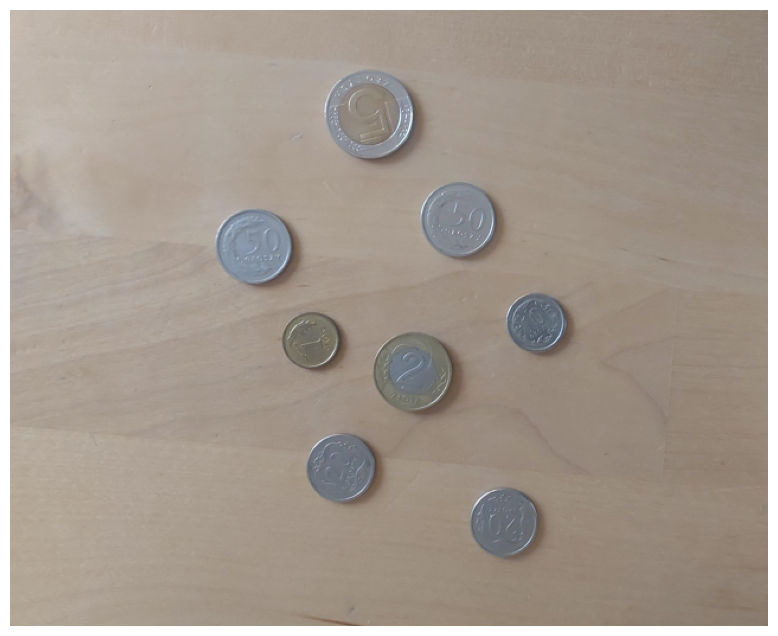

In [15]:
sample = data[0]

image = sample["image"]
boxes = sample["boxes"]
labels = sample["labels"]

print("Image size:", image.size)
print("Number of coins:", len(boxes))
print("Bounding boxes:", boxes)
print("Coin classes:", labels)

plt.figure(figsize=(10, 8))
plt.imshow(image)
plt.axis("off")
plt.show()

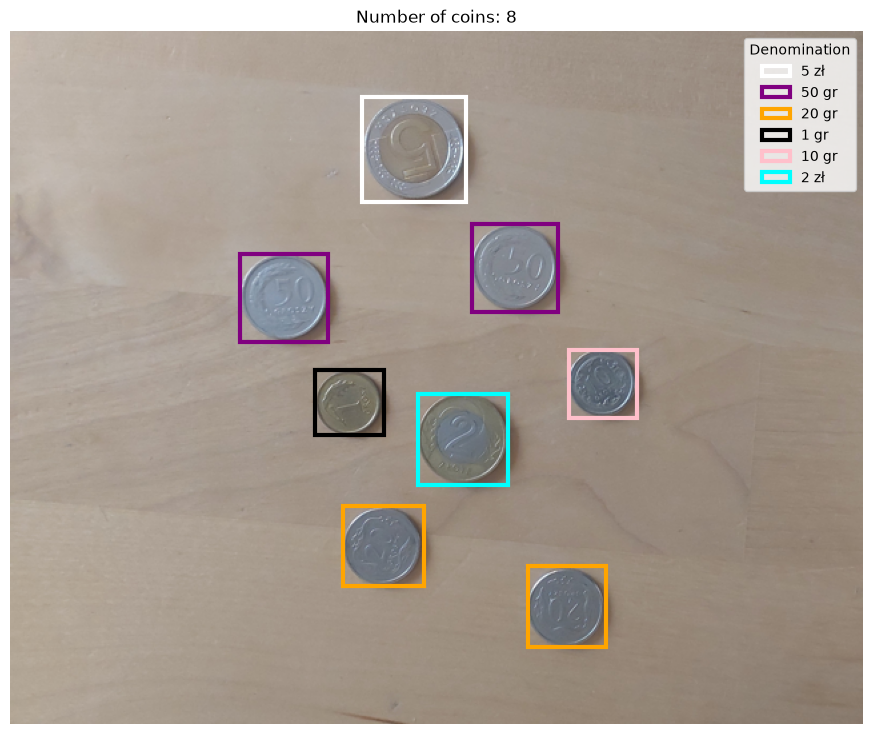

In [16]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

sample = data[0]

image = sample["image"]
boxes = sample["boxes"]
labels = sample["labels"]

CLASS_NAMES = [
    "1 gr", "2 gr", "5 gr",
    "10 gr", "20 gr", "50 gr",
    "1 zł", "2 zł", "5 zł"
]

colors = {
    0: "black",
    1: "red",
    2: "blue",
    3: "pink",
    4: "orange",
    5: "purple",
    6: "green",
    7: "cyan",
    8: "white",
    9: "black"

}

fig, ax = plt.subplots(figsize=(12, 9))

ax.imshow(image)

for box, label in zip(boxes, labels):
    x1, y1, x2, y2 = box.tolist()
    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        edgecolor=colors[int(label)],
        linewidth=3,
        facecolor="none",
        label=CLASS_NAMES[int(label)]
    )
    ax.add_patch(rect)

handles, labels = ax.get_legend_handles_labels()
unique = dict(zip(labels, handles))

ax.legend(unique.values(), unique.keys(), title="Denomination")
ax.set_title(f"Number of coins: {len(boxes)}")
ax.axis("off")
plt.show()

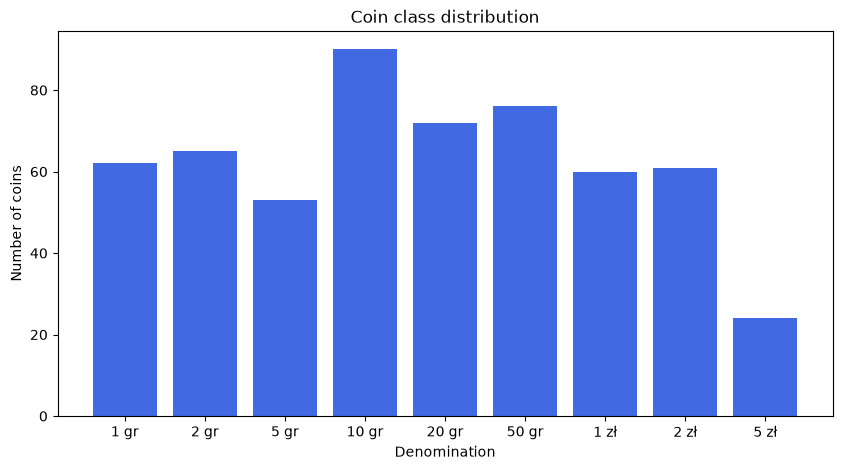

1 gr: 62
2 gr: 65
5 gr: 53
10 gr: 90
20 gr: 72
50 gr: 76
1 zł: 60
2 zł: 61
5 zł: 24


In [17]:
class_counts = numpy.zeros(len(CLASS_NAMES), dtype=int)

for sample in data:
    for label in sample["labels"]:
        class_counts[int(label)] += 1

plt.figure(figsize=(10, 5))
plt.bar(CLASS_NAMES, class_counts, color="royalblue")
plt.title("Coin class distribution")
plt.xlabel("Denomination")
plt.ylabel("Number of coins")
plt.show()

for name, count in zip(CLASS_NAMES, class_counts):
    print(f"{name}: {count}")

Minimum coins per image: 3
Maximum coins per image: 20
Average coins per image: 10.826923076923077


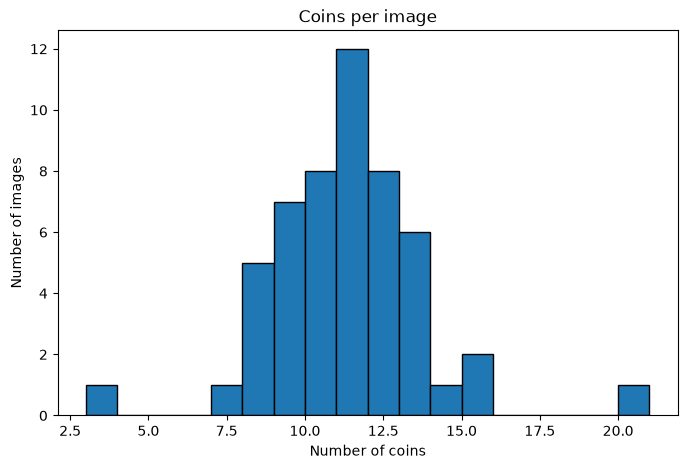

In [18]:
coins_per_image = [len(sample["boxes"]) for sample in data]

print("Minimum coins per image:", min(coins_per_image))
print("Maximum coins per image:", max(coins_per_image))
print("Average coins per image:", numpy.mean(coins_per_image))

plt.figure(figsize=(8, 5))
plt.hist(coins_per_image, bins=range(min(coins_per_image), max(coins_per_image) + 2), edgecolor="black")
plt.title("Coins per image")
plt.xlabel("Number of coins")
plt.ylabel("Number of images")
plt.show()

Average box width: 61.91651865008881
Average box height: 61.772646536412076


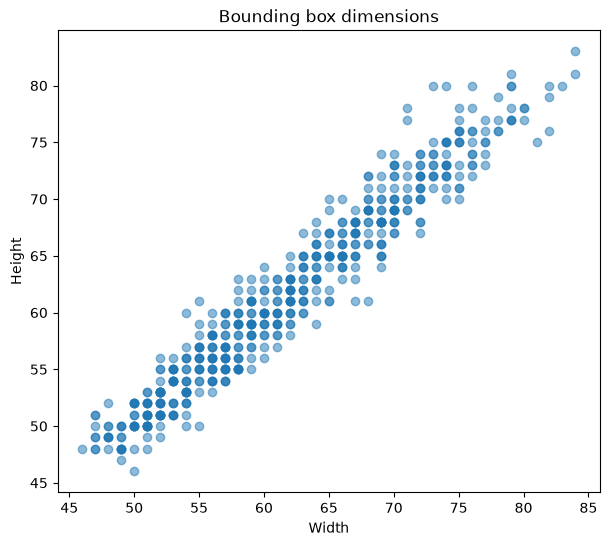

In [19]:
box_widths = []
box_heights = []

for sample in data:
    for x1, y1, x2, y2 in sample["boxes"]:
        box_widths.append(float(x2 - x1))
        box_heights.append(float(y2 - y1))

print("Average box width:", numpy.mean(box_widths))
print("Average box height:", numpy.mean(box_heights))

plt.figure(figsize=(7, 6))
plt.scatter(box_widths, box_heights, alpha=0.5)
plt.title("Bounding box dimensions")
plt.xlabel("Width")
plt.ylabel("Height")
plt.show()

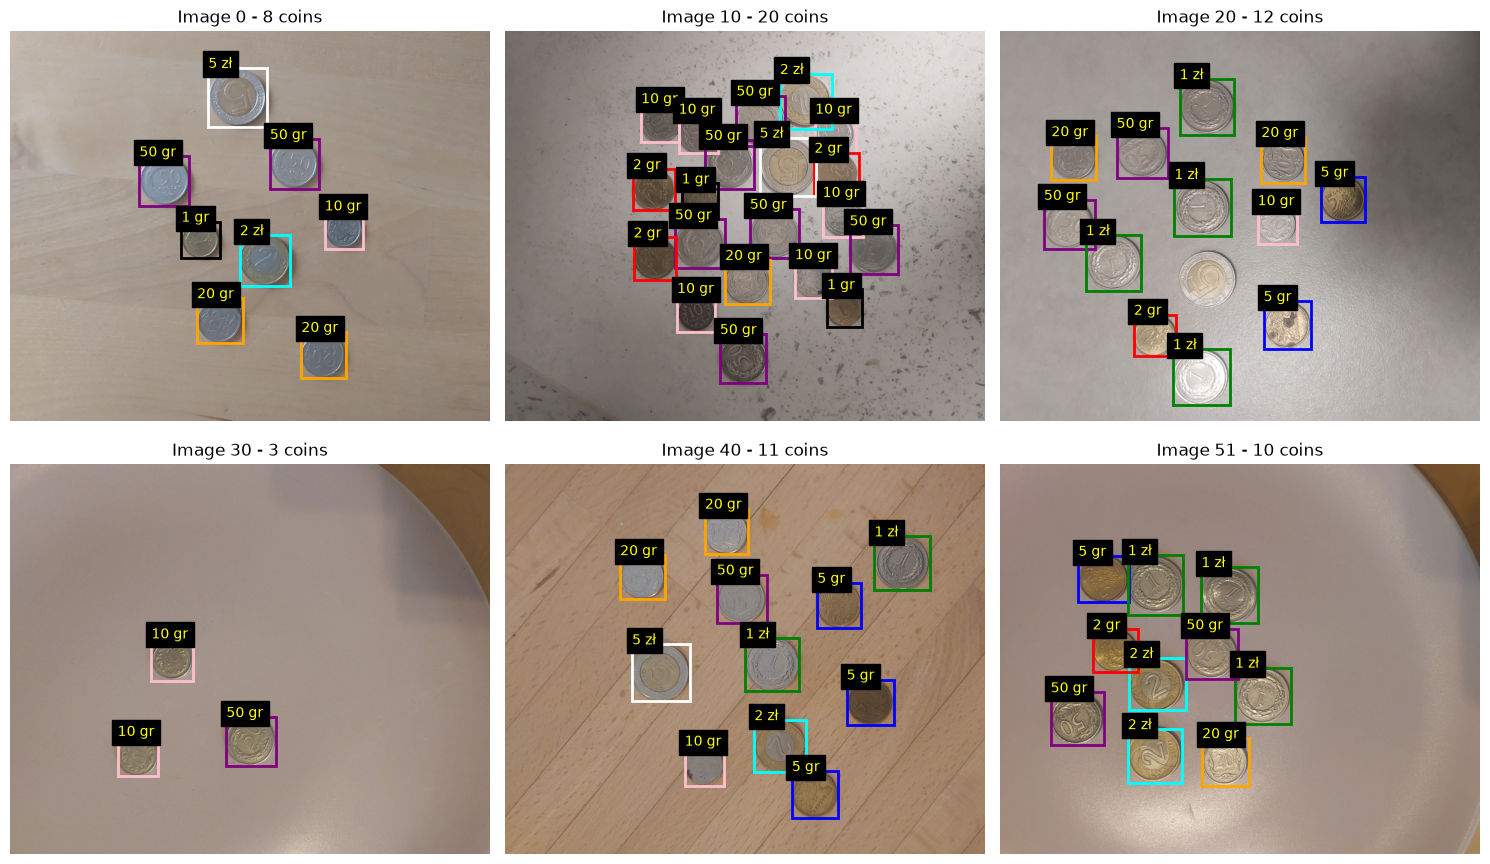

In [20]:
indices = numpy.linspace(0, len(data) - 1, 6, dtype=int)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, index in zip(axes.flat, indices):
    sample = data[index]
    ax.imshow(sample["image"])

    for box, label in zip(sample["boxes"], sample["labels"]):
        x1, y1, x2, y2 = box.tolist()
        rectangle = patches.Rectangle((x1, y1), x2 - x1, y2 - y1, edgecolor=colors[int(label)], linewidth=2, facecolor="none")
        ax.add_patch(rectangle)
        ax.text(x1, y1, CLASS_NAMES[int(label)], color="yellow", backgroundcolor="black")

    ax.set_title(f"Image {index} - {len(sample['boxes'])} coins")
    ax.axis("off")

plt.tight_layout()
plt.show()

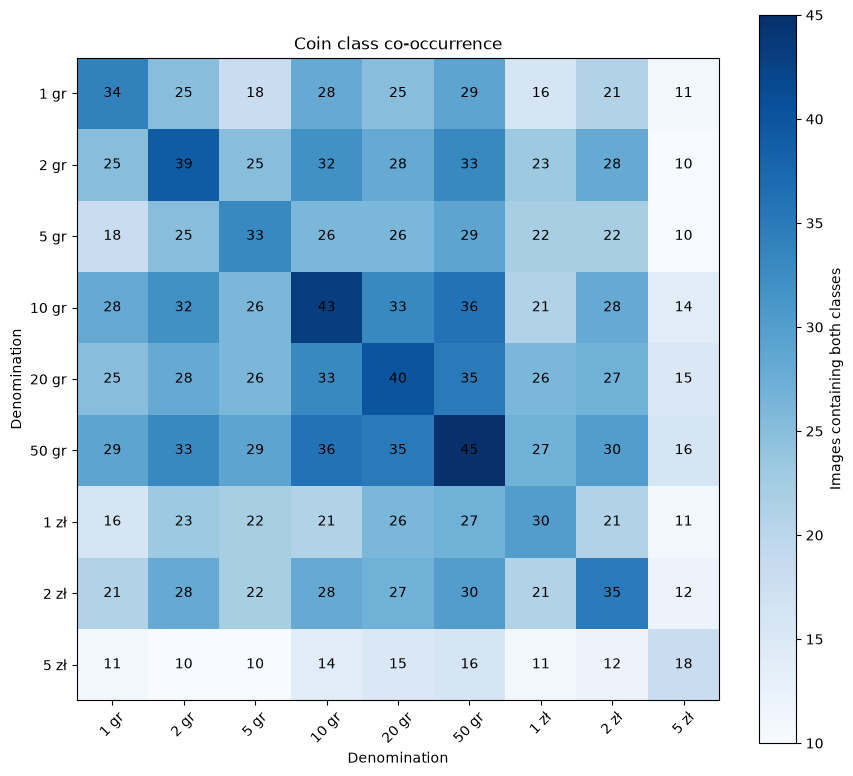

In [21]:
co_occurrence = numpy.zeros((len(CLASS_NAMES), len(CLASS_NAMES)), dtype=int)

for sample in data:
    present_classes = numpy.unique(sample["labels"].numpy())

    for first_class in present_classes:
        for second_class in present_classes:
            co_occurrence[int(first_class), int(second_class)] += 1

fig, ax = plt.subplots(figsize=(9, 8))
image_plot = ax.imshow(co_occurrence, cmap="Blues")
ax.set_xticks(range(len(CLASS_NAMES)), labels=CLASS_NAMES, rotation=45)
ax.set_yticks(range(len(CLASS_NAMES)), labels=CLASS_NAMES)
ax.set_title("Coin class co-occurrence")
ax.set_xlabel("Denomination")
ax.set_ylabel("Denomination")

for row in range(len(CLASS_NAMES)):
    for column in range(len(CLASS_NAMES)):
        ax.text(column, row, co_occurrence[row, column], ha="center", va="center")

fig.colorbar(image_plot, ax=ax, label="Images containing both classes")
plt.tight_layout()
plt.show()

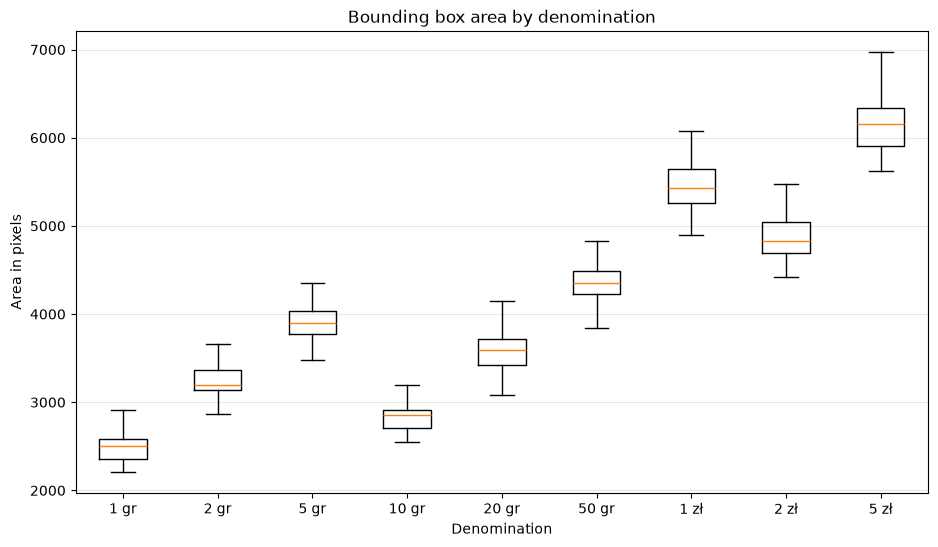

In [22]:
box_areas_by_class = [[] for _ in CLASS_NAMES]

for sample in data:
    for box, label in zip(sample["boxes"], sample["labels"]):
        x1, y1, x2, y2 = box.tolist()
        box_areas_by_class[int(label)].append((x2 - x1) * (y2 - y1))

plt.figure(figsize=(11, 6))
plt.boxplot(box_areas_by_class, tick_labels=CLASS_NAMES, showfliers=False)
plt.title("Bounding box area by denomination")
plt.xlabel("Denomination")
plt.ylabel("Area in pixels")
plt.grid(axis="y", alpha=0.3)
plt.show()